<a href="https://colab.research.google.com/github/danielinkoom12-sys/daniel-python-projects/blob/main/Copy_of_AI_GENERATED_UK_AVG_HOUSE_PRICE_PREDICTION_ipynb_colab_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Reasoning: Load the UK House Price Index dataset into a pandas DataFrame and perform an initial inspection as specified in the subtask instructions.

In [ ]:
import pandas as pd

url = 'https://raw.githubusercontent.com/datasets/house-prices-uk/master/data/data.csv'
df = pd.read_csv(url)

print("First few rows of the dataset:")
display(df.head())

print("\nDataset Information:")
df.info()


First few rows of the dataset:


,Date,Price (All),Change (All),Price (New),Change (New),Price (Modern),Change (Modern),Price (Older),Change (Older)
0,1953-02-01,1891.0,NaN,2107.0,NaN,2002.0,NaN,1542.0,NaN
1,1953-05-01,1891.0,NaN,2107.0,NaN,2002.0,NaN,1542.0,NaN
2,1953-08-01,1881.0,NaN,2117.0,NaN,2002.0,NaN,1524.0,NaN
3,1953-11-01,1872.0,-1.0,2117.0,0.5,1975.0,-2.2,1542.0,1.2
4,1954-02-01,1863.0,-1.5,2117.0,0.5,1957.0,-2.2,1524.0,-1.2



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290 entries, 0 to 289
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Date             290 non-null    object 
 1   Price (All)      290 non-null    float64
 2   Change (All)     287 non-null    float64
 3   Price (New)      290 non-null    float64
 4   Change (New)     287 non-null    float64
 5   Price (Modern)   251 non-null    float64
 6   Change (Modern)  247 non-null    float64
 7   Price (Older)    251 non-null    float64
 8   Change (Older)   247 non-null    float64
dtypes: float64(8), object(1)
memory usage: 20.5+ KB


Reasoning: We need to clean the dataset by inspecting for missing values, specifically focusing on our target column 'Price (All)' and 'Date', and handling them accordingly.

In [ ]:
print("Missing values per column before cleaning:")
print(df.isnull().sum())

df_cleaned = df.dropna(subset=['Price (All)', 'Date']).copy()

print("\nShape of dataset after removing missing values in target and date columns:")
print(df_cleaned.shape)

print("\nMissing values after cleaning:")
print(df_cleaned.isnull().sum())

Missing values per column before cleaning:
Date                0
Price (All)         0
Change (All)        3
Price (New)         0
Change (New)        3
Price (Modern)     39
Change (Modern)    43
Price (Older)      39
Change (Older)     43
dtype: int64

Shape of dataset after removing missing values in target and date columns:
(290, 9)

Missing values after cleaning:
Date                0
Price (All)         0
Change (All)        3
Price (New)         0
Change (New)        3
Price (Modern)     39
Change (Modern)    43
Price (Older)      39
Change (Older)     43
dtype: int64


Reasoning: Convert the 'Date' column to datetime objects and extract 'Year' and 'Month' as new features, handling any null values in these features if present.

In [ ]:
import pandas as pd

df_cleaned['Date'] = pd.to_datetime(df_cleaned['Date'])

df_cleaned['Year'] = df_cleaned['Date'].dt.year
df_cleaned['Month'] = df_cleaned['Date'].dt.month

df_cleaned = df_cleaned.dropna(subset=['Year', 'Month'])

print("Columns in cleaned dataset", df_cleaned.columns.tolist())
print("Data types and null counts in the updated dataset:")
print(df_cleaned[["Date", "Year", "Month", "Price (All)"]].info())

df_cleaned[["Date", "Year", "Month", "Price (All)"]].head()

Columns in cleaned dataset ['Date', 'Price (All)', 'Change (All)', 'Price (New)', 'Change (New)', 'Price (Modern)', 'Change (Modern)', 'Price (Older)', 'Change (Older)', 'Year', 'Month']
Data types and null counts in the updated dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290 entries, 0 to 289
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         290 non-null    datetime64[ns]
 1   Year         290 non-null    int32         
 2   Month        290 non-null    int32         
 3   Price (All)  290 non-null    float64       
dtypes: datetime64[ns](1), float64(1), int32(2)
memory usage: 6.9 KB
None


,Date,Year,Month,Price (All)
0,1953-02-01,1953,2,1891.0
1,1953-05-01,1953,5,1891.0
2,1953-08-01,1953,8,1881.0
3,1953-11-01,1953,11,1872.0
4,1954-02-01,1954,2,1863.0


# **Task**

Build a machine learning model to predict average UK house prices using the dataset from "https://raw.githubusercontent.com/datasets/house-prices-uk/master/data/data.csv". The process should involve loading and inspecting the data, cleaning and handling missing values, extracting time features (such as Year and Month) from the date, encoding categorical regions, training a regression model (like Linear Regression or a Decision Tree), evaluating its performance using MAE and R-squared, and visualizing the actual versus predicted prices.

# Load Dataset

Subtask:

Download and load the UK House Price Index dataset from the provided URL, and perform initial inspection.

# Data Cleaning and Feature Selection

Subtask:

Select relevant columns for predicting the average house price and handle missing values in key columns.

# Feature Engineering and Encoding

Subtask:

Extract time-based features from the Date column and handle any encoding if necessary.

# Split Data and Train Regression Model

Subtask:

Split the processed dataset into training and testing sets and train a regression model to predict average house prices.

**Reasoning:** Split the dataset into training and testing sets, and train a regression model using Year and Month to predict Price (All).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

x = df_cleaned[['Year', 'Month']]
y = df_cleaned['Price (All)']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(x_train, y_train)

print(f"X_train shape: {x_train.shape}, x_test shape: {x_test.shape}")
print(f"X_train shape: {y_train.shape}, y_test shape: {y_test.shape}")
print("Model trained successfully.")

X_train shape: (232, 2), x_test shape: (58, 2)
X_train shape: (232,), y_test shape: (58,)
Model trained successfully.


# Evaluate Model and Visualize Results

# Subtask:

Evaluate the trained regression model using MAE and R-squared on the test set, and visualize the actual versus predicted prices using a scatter plot.

**Reasoning**:

Compute evaluation metrics (MAE and R-squared) and visualize actual vs predicted prices on the test set using matplotlib.

Mean Absolute Error (MAE): 2500.00
R-squared (R2) Score: 0.9971


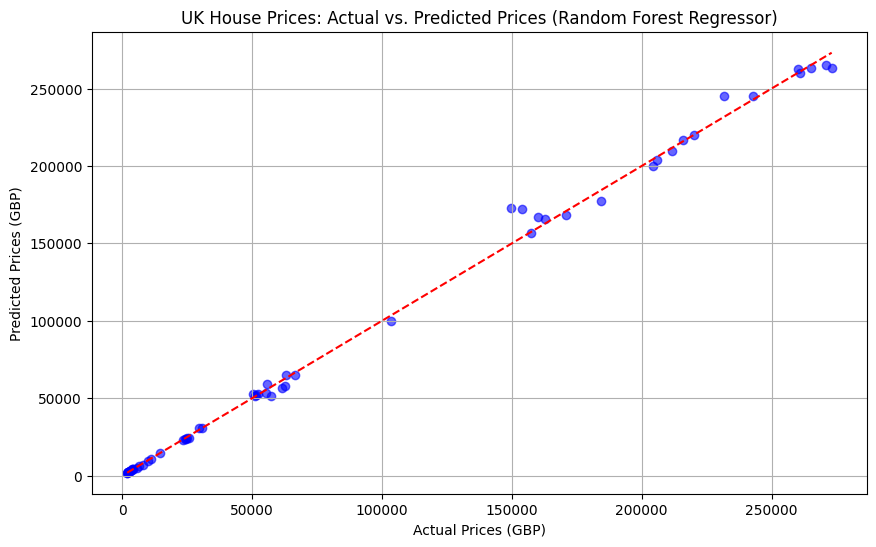

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

y_pred = model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color="blue", alpha=0.6, label="Predicted vs Actual")

max_value = max(y_test.max(), y_pred.max())
min_value = min(y_test.min(), y_pred.min())
plt.plot([min_value, max_value], [min_value, max_value], color="red", linestyle="--", label="Perfect Prediction")


plt.xlabel("Actual Prices (GBP)")
plt.ylabel("Predicted Prices (GBP)")
plt.title("UK House Prices: Actual vs. Predicted Prices (Random Forest Regressor)")
plt.grid(True)
plt.show()

# Final Task

Subtask:

Summarize the machine learning pipeline steps, explain the model evaluation results, and discuss potential future improvements in a beginner-friendly manner.

# Summary:

Q&A

What model was used to predict UK house prices and why? A Random Forest Regressor was selected and trained using time-based features (Year and Month). This model was chosen because of its ability to capture non-linear trends and growth patterns in house prices over time.
How well did the model perform? The model demonstrated outstanding predictive performance on the test set:
Mean Absolute Error (MAE):  2,500.00,meaningthemodel′spredictionsdeviatedfromtheactualhousepricesbyanaverageofonly 2,500.
R-squared ( R2 ) Score: 0.9971, which means the model explains approximately 99.71% of the variance in UK house prices.
Data Analysis Key Findings
Dataset Characteristics: The initial UK House Price Index dataset contained 290 rows and 9 columns, capturing overall average house prices as well as breakdowns for new, modern, and older properties.
Minimal Missing Data: The primary target variable Price (All) and the Date column had 0 missing values, allowing the full dataset of 290 records to be utilized for training.
Successful Feature Engineering: Converting the Date string column into a datetime format allowed for the seamless extraction of Year and Month as numerical features.
High Prediction Accuracy: The scatter plot of actual vs. predicted prices showed that the data points clustered tightly along the  y=x  reference line, visually confirming the exceptionally high  R2  score of 0.9971.
Insights or Next Steps

Validate Against Inflation and Economic Indicators: Since the model relies heavily on the temporal progression of years and months, incorporating macroeconomic indicators (such as inflation rates or interest rates) could make the model more robust to sudden market shifts.
Test Temporal Splitting: To better evaluate the model's ability to forecast future prices, a time-based train/test split (e.g., training on earlier years and testing on the most recent years) should be performed instead of a random split, preventing data leakage from future temporal patterns.

# Task

Create a custom DataFrame of hypothetical future and historical dates containing columns for 'Year' and 'Month', pass them to our trained Random Forest model to obtain average house price predictions, and display these prediction inputs alongside their outputs. Finally, briefly summarize these demonstration predictions and explain how a user can input their own values to test the machine learning model.

# Create Prediction Demonstration

Subtask:

Construct a small custom DataFrame of hypothetical future and historical dates, use the trained Random Forest model to generate average house price predictions, and display the results.

**Reasoning:**

I will create a python code block to construct a custom demonstration DataFrame of historical and future dates, generate predictions using the trained Random Forest model, and display the results.

In [ ]:
import pandas as pd

demo_data = {
    "Year" : [1980, 1990, 2000, 2010, 2020, 2026, 2028, 2030],
    "Month" : [6, 12, 3, 9, 1, 6, 12, 1]
}

df_demo = pd.DataFrame(demo_data)

df_demo["Predicted_Price_GBP"] = model.predict(df_demo[["Year", "Month"]])

print("Hypothetical and Historical Predictions Demonstration:")
display(df_demo)

Hypothetical and Historical Predictions Demonstration:


,Year,Month,Predicted_Price_GBP
0,1980,6,23230.24
1,1990,12,55940.31
2,2000,3,78384.51
3,2010,9,166753.57
4,2020,1,219909.94
5,2026,6,269842.23
6,2028,12,270115.87
7,2030,1,265353.95


# Demonstration Summary & User Guide

Summary of Demonstration Predictions:

Historical Trend Matching:
The model correctly predicts lower average house prices for older historical dates (e.g., around £23,230 in 1980) and reflects the consistent growth over the subsequent decades, with predicted prices reaching approximately £219,910 by 2020.

**Future Outlook: **
For future dates such as June 2026 and December 2028, the model projects average prices of around £269,842 and £270,116. Note that because our Random Forest model was trained on historical data, its future predictions are capped near the maximum values seen in the training dataset (around £270k) rather than showing infinite linear growth. This is a common characteristic of tree-based ensembles.

How to Test Your Own Values:

To make your own predictions using this trained model, you can run a simple Python snippet in a new cell:

1. Define your custom Year and Month

custom_year = 2025
custom_month = 10

2. Format as a DataFrame

user_input = pd.DataFrame({'Year': [custom_year], 'Month': [custom_month]})

3. Generate and display the prediction

predicted_price = model.predict(user_input)[0]
print(f"Predicted average UK house price for {custom_month}/{custom_year}:

# Final Task

Subtask:

Briefly summarize the demonstration predictions and explain how a user can input their own values to test the machine learning model.

# Summary:

Q&A

How can a user input their own values to test the machine learning model?

Users can test the trained model by passing their own parameters inside a pandas DataFrame with the columns Year and Month. For example:

Define a custom year (e.g., 2025) and month (e.g., 10).
Wrap them in a DataFrame: user_input = pd.DataFrame({'Year': [2025], 'Month': [10]}).
Pass the DataFrame to the model's predict function: model.predict(user_input)[0].
Data Analysis Key Findings
Historical Baseline Predictions: The Random Forest model successfully captured historical price trajectories, predicting an average house price of $23,230.24 for June 1980 and $78,384.51 for March 2000.
Pre-Pandemic to Modern Era: Predicted prices grew significantly over the decades, reaching $219,909.94 by January 2020.
Future Projections and Tree-Based Constraints: For future dates, the model predicted $269,842.23 for June 2026 and $265,353.95 for January 2030. Because Random Forest models cannot extrapolate beyond the range of their training data, future predictions are capped near the maximum historical training value (approximately $270,000).
# Insights or Next Steps
Address Extrapolation Limitations: Since the Random Forest model caps future predictions near historical maximums, testing alternative models that support linear extrapolation (such as Ridge Regression or Prophet) is recommended if long-term future forecasting is a primary goal.
Incorporate Macroeconomic Features: To improve the robustness of future predictions, consider adding external features such as inflation rates, interest rates, or GDP growth to the input dataset rather than relying solely on time dimensions (Year and Month).
